# ML1 - GridSearch avec DecisionTreeRegression, RandomForestRegressor

Ce notebook fait suite au notebook ML1_Pipeline_Model et se concentre sur :
1. L'utilisation de DecisionTreeRegressor et RandomForestRegressor ou d'autres
2. L'optimisation des hyperparamètres avec GridSearchCV
3. La validation croisée (cross-validation)

## 1. Import des bibliothèques

In [61]:
# Les libraries nécessaires
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import cross_val_score, cross_val_predict
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LassoCV

from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

## 2. Chargement et préparation des données avec le PipeLine.

Nous reprenons les mêmes étapes de préparation que dans le notebook précédent.

In [7]:
# Chargement des données depuis le fichier pickle
df = pd.read_pickle('/home/sami.chircop@Digital-Grenoble.local/Documents/ML1/data/trees.pkl')

df['Latitude'] = df['Latitude'].map(lambda x:float(x))
df['Longitude'] = df['Longitude'].map(lambda x:float(x))
df['adr_secteur'] = df['adr_secteur'].map(lambda x:str(x))

annee = df.pop('anneedeplantation')

X_train, X_test, y_train, y_test = train_test_split(df, annee, random_state=28)

cat_var = df.select_dtypes(include=str).columns.tolist()
num_var = df.select_dtypes(exclude=str).columns.tolist()

transformer = ColumnTransformer([
    ("Numerical standardization", StandardScaler(), num_var),
     ("Categorical standardization", OneHotEncoder(handle_unknown='ignore'), cat_var)
])
#ridge needs sparce = False
X_prepared = transformer.fit_transform(X_train)
X_test_prepared = transformer.transform(X_test)


## 3. Cross-validation initiale

Avant d'optimiser les hyperparamètres, évaluons un modèle avec les paramètres par défaut en utilisant la validation croisée.

In [ ]:
# Validation croisée initiale sans optimisation des hyperparamètres
# On peut aussi imprimer les scores MSE ou MAE de chaque cross-validation.

model_0 = RandomForestRegressor(max_depth=5)
model_0.fit(X_prepared, y_train)

# predict y values for testing data set
y_pred_test = cross_val_predict(model_0, X_test_prepared, y_test, cv = 5)
mse_test = mean_squared_error(y_test, y_pred_test)
print('test MSE: {0}'.format(mse_test))

#Cross-validation
cv_scores = cross_val_score(model_0, X_prepared, y_train, cv = 5, scoring='neg_mean_squared_error')
print('mean CV MSE:',np.mean(-cv_scores))
print(-cv_scores)

test MSE: 57.055238959631524
mean CV MSE: 35.35477444544282
[36.0927126  32.11974107 34.64111863 41.6778056  32.24249433]


## 4. 🌳 Modélisation avec GridSearchCV

Choisissons deux models de machine learning.

Évaluer les modèles avec optimisation (en testant différentes valeurs des hyperparamètres).
Optimisez les modèles comme vous le souhaitez, par exemple pour l'arbre des des decisions et forêt aléatoire :

### 🔍 Hyperparamètres testés
- `max_depth`: profondeur maximale des arbres [3, 4, 5, 10]
- `min_samples_leaf`: nombre minimum d'échantillons requis dans une feuille [0.1, 0.05]
- `n_estimators` (pour la forêt aléatoire uniquement) : nombre d'arbres dans la foret [50, 100, 200]

Utilisons GridSearchCV pour automatiser la recherche des meilleurs hyperparamètres.

In [13]:
# Optimisation des hyperparamètres avec GridSearchCV et on peut imprimer les score MSE ou MAE de chaque cross-validation.
#pipeline = Pipeline(
#        ("classifier", RandomForestRegressor())
#)

param_grid = {
    'max_depth': [3, 4, 5, 10],
    'min_samples_leaf': [0.1, 0.05],
    'n_estimators': [50, 100, 200]
}

#ridge needs sparce = False
forest_grid = GridSearchCV(RandomForestRegressor(), param_grid, cv=5, scoring='neg_mean_squared_error')
forest_grid.fit(X_prepared, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestRegressor()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [3, 4, ...], 'min_samples_leaf': [0.1, 0.05], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, d

## 5. Évaluation finale sur le set de test

In [24]:
# Code pour l'evaluation du meilleur modèle sur le set de test.
forresults = pd.DataFrame(forest_grid.cv_results_)

y_pred = forest_grid.predict(X_test_prepared)
mse = mean_squared_error(y_test, y_pred)
best_cv_mse = -forest_grid.best_score_

print('CV-MSE MSE ', best_cv_mse)
print('Test MSE: ', mse)

CV-MSE MSE  179.37260363008554
Test MSE:  179.3527338766585


## 6. Visualisation des prédictions
Un seul model suffira.

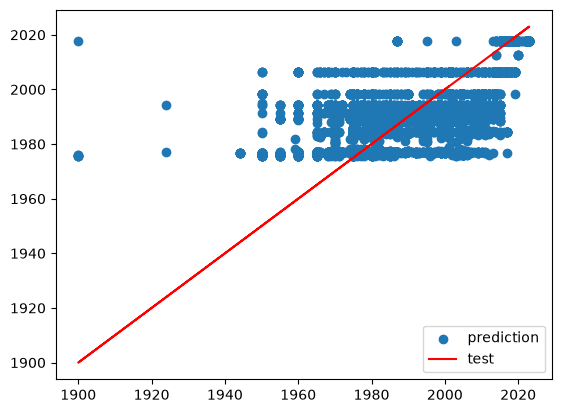

In [25]:
# Visualisation des prédictions.
plt.scatter(y_test, y_pred)
plt.plot(y_test,y_test, 'r')
plt.legend(['prediction','test'])

## 7. [OPTIONNEL] Importance des features

En utilisant la forêt aléatoire, comment peut-on savoir quelles sont les features les plus importantes ?

In [53]:
# Code, et à votre avis, comment etait calculé l'importance des features dans la forêt aléatoire ?
# Extract feature importances
bm = forest_grid.best_estimator_
importances = bm.feature_importances_

feature_names = transformer.get_feature_names_out()
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})

# Rank features by importance
feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False)
print(feature_importance_df[:10])

# Select top N features (example selecting top 10 features)
top_features = feature_importance_df['Feature'][:10].values


                                               Feature  Importance
410  Categorical standardization__stadededeveloppem...    0.643032
413  Categorical standardization__stadededeveloppem...    0.107873
417  Categorical standardization__hauteurarbre_Moin...    0.082067
1                 Numerical standardization__Longitude    0.065852
439        Categorical standardization__typenature_nan    0.037321
100   Categorical standardization__genre_bota_Platanus    0.028585
427         Categorical standardization__portarbre_nan    0.025832
431  Categorical standardization__structure_Ville d...    0.003813
430  Categorical standardization__structure_Métropo...    0.001854
7    Categorical standardization__sous_categorie_de...    0.001565


Typiquement, on pourrait envisager de faire une backward elimination sur l'importance des features pour sélectionner le meilleur sous ensemble de features, mais cela peut-etre long si on a beaucoup de features et un modèle un peu long à entrainer comme c'est le cas ici. À la place on peut utiliser une regression avec regularisation lasso pour éliminer des features, avant de ré-entrainer une RandomForest sur les features sélectionnées. Créez un pipeline avec `LassoCV` comme selector et une RandomForest avec les meilleurs hyper-paramètres trouvés par la grid search en model. Évaluez sur le set de test.


In [86]:
# Code
#forest_grid.best_params_
forest_params = {
    'max_depth': 10,
    'min_samples_leaf': 0.05,
    'n_estimators': 100
}

selector = LassoCV(cv = 5, random_state=28)
regressor = RandomForestRegressor(forest_params)

full_pipeline = Pipeline([
    ("selector", selector), 
    ("regressor", regressor)])

full_pipeline.fit(X_prepared, y_train)

TypeError: All intermediate steps should be transformers and implement fit and transform or be the string 'passthrough' 'LassoCV(cv=5, random_state=28)' (type <class 'sklearn.linear_model._coordinate_descent.LassoCV'>) doesn't

## 8. [OPTIONNEL] Comparez différents modèles de regression

Comparez plus de modèles de régression entre eux (par exemple en plus de la régression linéaire, des arbres de décision et des forets, le `GradientBoostingRegressor`, et le plus récent `TabICLRegressor` si vous avez le temps ( https://github.com/soda-inria/tabicl )), en faisant une recherche d'hyperparamètre adéquate à chaque modèle :

In [ ]:
#Code, cherchez des examples pour trouver quels sont les hyper-parametres importants pour chaque modèle

Choisissez le modèle qui marche le mieux et ses meilleurs hyper-paramètres, sélectionnez le meilleur sous-ensemble de features pour ce modèle, et enfin refaites une dernière grid-search sur les hyper-paramètres de votre modèle avec les features retenues, pour obtenir votre modèle final. Évaluez sur le test set.

In [ ]:
#Code

## Conclusion